In [19]:

import os
import glob
import zipfile

# Find the uploaded smaller ZIP file
zip_files = glob.glob('/content/*small*.zip')

print("ZIP files found:", zip_files)

if not zip_files:
    print("Please upload indian_house_price_small.zip first.")
else:
    with zipfile.ZipFile(zip_files[0], 'r') as z:
        z.extractall('/content/indian_house_data')

    print("Extraction successful!")
    print(os.listdir('/content/indian_house_data'))


ZIP files found: ['/content/indian_house_price_small.zip']
Extraction successful!
['test.csv', 'train.csv', 'sample_submission.csv', 'metaData.csv']


In [20]:

import pandas as pd
import os

data_folder = '/content/indian_house_data'

# Find train.csv even if it is inside a subfolder
matches = glob.glob(data_folder + '/**/train.csv', recursive=True)

if not matches:
    print("train.csv not found. Check the extracted filenames.")
else:
    train_df = pd.read_csv(matches[0])
    print("Dataset loaded successfully!")
    print("Rows and columns:", train_df.shape)
    display(train_df.head())


Dataset loaded successfully!
Rows and columns: (5000, 18)


,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
0,PROP-025768,Chennai,Premium,Villa,3,4,3202.62,2125.63,2,8,17,Furnished,0,1,1,1.18,5.58,333.73
1,PROP-010675,Bangalore,Mid-Range,Independent House,5,6,884.90,653.09,22,30,20,Semi-Furnished,1,1,0,4.63,10.36,112.09
2,PROP-022040,Bangalore,Affordable,Apartment,6,6,674.12,533.37,8,10,32,Unfurnished,1,1,0,2.27,6.59,66.90
3,PROP-088043,Jaipur,Mid-Range,Independent House,2,3,975.60,644.61,19,33,6,Unfurnished,1,1,1,5.23,2.56,30.08
4,PROP-046826,Delhi,Mid-Range,Builder Floor,2,3,905.54,693.20,2,3,22,Unfurnished,0,1,0,1.32,6.49,177.49


In [21]:

print("Dataset size:", train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isnull().sum().sort_values(ascending=False).head(10))


Dataset size: (5000, 18)

Column names:
['Property_ID', 'City', 'Locality_Type', 'Property_Type', 'BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Furnishing_Status', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km', 'Price_INR_Lakhs']

Missing values:
Property_ID         0
City                0
Locality_Type       0
Property_Type       0
BHK                 0
Bathrooms           0
Super_Area_SqFt     0
Carpet_Area_SqFt    0
Floor_Number        0
Total_Floors        0
dtype: int64


In [22]:

# Find the price column
price_columns = [
    col for col in train_df.columns
    if 'price' in col.lower()
]

print("Possible price columns:", price_columns)


Possible price columns: ['Price_INR_Lakhs']


In [23]:

# Find the target price column automatically
price_columns = [
    col for col in train_df.columns
    if 'price' in col.lower()
]

if len(price_columns) != 1:
    print("Please check the price columns:", price_columns)
else:
    target = price_columns[0]

    # Separate inputs and target price
    X = train_df.drop(columns=[target])
    y = train_df[target]

    print("Target column:", target)
    print("Input data shape:", X.shape)
    print("Target data shape:", y.shape)
    print("Data preparation completed!")


Target column: Price_INR_Lakhs
Input data shape: (5000, 17)
Target data shape: (5000,)
Data preparation completed!


In [24]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training houses:", len(X_train))
print("Testing houses:", len(X_test))


Training houses: 4000
Testing houses: 1000


In [25]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numeric and text columns
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()

# Fill missing numeric values
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Fill missing text values and encode categories
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Preprocessing completed!")


Numeric features: 12
Categorical features: 5
Preprocessing completed!


In [26]:

from sklearn.linear_model import Ridge

model = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', Ridge(alpha=1.0, solver='lsqr'))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [27]:

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Predict prices for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score: {r2:.4f}")
print(f"R² Percentage: {r2 * 100:.2f}%")
print(f"MAE: ₹{mae:.2f} lakhs")
print(f"RMSE: ₹{rmse:.2f} lakhs")


R² Score: 0.6902
R² Percentage: 69.02%
MAE: ₹48.15 lakhs
RMSE: ₹86.24 lakhs


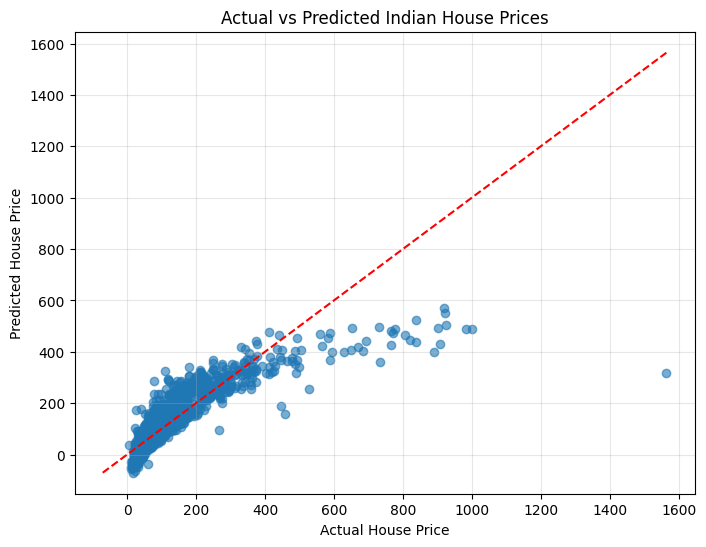

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction reference line
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--')

plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual vs Predicted Indian House Prices')
plt.grid(alpha=0.3)
plt.show()


In [29]:

one_house = X_test.iloc[[0]]

predicted_price = model.predict(one_house)[0]
actual_price = y_test.iloc[0]

print(f"Predicted price: {predicted_price:.2f}")
print(f"Actual price:    {actual_price:.2f}")
print(f"Absolute error:  {abs(predicted_price - actual_price):.2f}")


Predicted price: 178.53
Actual price:    39.78
Absolute error:  138.75


In [30]:

print("Enter these features to predict a house price:\n")

for col in X.columns:
    print(f"{col}: example = {X[col].dropna().iloc[0] if not X[col].dropna().empty else 'No example'}")


Enter these features to predict a house price:

Property_ID: example = PROP-025768
City: example = Chennai
Locality_Type: example = Premium
Property_Type: example = Villa
BHK: example = 3
Bathrooms: example = 4
Super_Area_SqFt: example = 3202.62
Carpet_Area_SqFt: example = 2125.63
Floor_Number: example = 2
Total_Floors: example = 8
Age_of_Property: example = 17
Furnishing_Status: example = Furnished
Parking: example = 0
Lift_Available: example = 1
Gated_Community: example = 1
Distance_to_Metro_km: example = 1.18
Distance_to_City_Center_km: example = 5.58


In [31]:

# Copy one house's details as a template
new_house = X.iloc[[0]].copy()

# Display the details
display(new_house.T.rename(columns={new_house.index[0]: "House details"}))

# Predict its price
predicted_price = model.predict(new_house)[0]

print(f"Estimated house price: {predicted_price:.2f} lakhs")


,House details
Property_ID,PROP-025768
City,Chennai
Locality_Type,Premium
Property_Type,Villa
BHK,3
Bathrooms,4
Super_Area_SqFt,3202.62
Carpet_Area_SqFt,2125.63
Floor_Number,2
Total_Floors,8


Estimated house price: 384.95 lakhs


In [32]:

import joblib

joblib.dump(model, '/content/indian_house_price_model.pkl')

print("Model saved successfully!")


Model saved successfully!


In [40]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
import time

rf_model = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=60,
        max_depth=18,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest R²:",
      round(r2_score(y_test, rf_pred) * 100, 2), "%")
print("Random Forest MAE:",
      round(mean_absolute_error(y_test, rf_pred), 2), "lakhs")
print("Time taken:", round(time.time() - start, 2), "seconds")


Random Forest R²: 78.47 %
Random Forest MAE: 37.27 lakhs
Time taken: 5.59 seconds
